In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import (silhouette_score, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score)
from scipy.cluster.hierarchy import linkage, dendrogram

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

In [2]:
# Adaptez le chemin si besoin (ex. "ProcessedData (1).xlsx")
import os
DATA_PATH = next(p for p in ["ProcessedData.xlsx", "ProcessedData (1).xlsx", "ProcessedData-1.xlsx",
                             "/mnt/user-data/uploads/ProcessedData-1.xlsx"] if os.path.exists(p))
df = pd.read_excel(r"C:\projetghaith\ProcessedData-1.xlsx")
print("Dimensions :", df.shape)
df.head()

Dimensions : (3866, 13)


,ID,AGE,EDUC,MARRIED,KIDS,LIFECL,OCCAT,RISK,HHOUSES,WSAVED,SPENDMOR,NWCAT,INCCL
0,1,3,2,1,0,2,1,3,1,1,5,3,4
1,2,4,4,1,2,5,2,3,0,2,5,5,5
2,3,3,1,1,2,3,2,2,1,2,4,4,4
3,4,3,1,1,2,3,2,2,1,2,4,3,4
4,5,4,3,1,1,5,1,2,1,3,3,5,5


In [3]:
df.info()
print("\nValeurs manquantes :", int(df.isna().sum().sum()))
print("Doublons (hors ID) :", int(df.drop(columns="ID").duplicated().sum()))
df.describe().T

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3866 entries, 0 to 3865
Data columns (total 13 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   ID        3866 non-null   int64
 1   AGE       3866 non-null   int64
 2   EDUC      3866 non-null   int64
 3   MARRIED   3866 non-null   int64
 4   KIDS      3866 non-null   int64
 5   LIFECL    3866 non-null   int64
 6   OCCAT     3866 non-null   int64
 7   RISK      3866 non-null   int64
 8   HHOUSES   3866 non-null   int64
 9   WSAVED    3866 non-null   int64
 10  SPENDMOR  3866 non-null   int64
 11  NWCAT     3866 non-null   int64
 12  INCCL     3866 non-null   int64
dtypes: int64(13)
memory usage: 392.8 KB

Valeurs manquantes : 0
Doublons (hors ID) : 0


,count,mean,std,min,25%,50%,75%,max
ID,3866.0,1933.500000,1116.162399,1.0,967.25,1933.5,2899.75,3866.0
AGE,3866.0,3.107346,1.512556,1.0,2.00,3.0,4.00,6.0
EDUC,3866.0,2.906363,1.066253,1.0,2.00,3.0,4.00,4.0
MARRIED,3866.0,1.353337,0.478068,1.0,1.00,1.0,2.00,2.0
KIDS,3866.0,0.937662,1.249059,0.0,0.00,0.0,2.00,8.0
LIFECL,3866.0,3.696844,1.617554,1.0,3.00,3.0,5.00,6.0
OCCAT,3866.0,1.741593,0.934443,1.0,1.00,1.0,3.00,4.0
RISK,3866.0,3.042938,0.879385,1.0,2.00,3.0,4.00,4.0
HHOUSES,3866.0,0.716503,0.450754,0.0,0.00,1.0,1.00,1.0
WSAVED,3866.0,2.445939,0.743267,1.0,2.00,3.0,3.00,3.0


**Lecture :** le jeu contient 3 866 individus et 13 colonnes, toutes numériques (codes ordinaux). Il n'y a ni valeur manquante ni doublon, donc aucune imputation n'est nécessaire.

| Variable | Sens (d'après la base SCF, à vérifier) |
|---|---|
| ID | identifiant (inutile pour le modèle) |
| AGE | tranche d'âge (1 à 6) |
| EDUC | niveau d'études (1 à 4) |
| MARRIED | 1 = en couple, 2 = seul |
| KIDS | nombre d'enfants |
| LIFECL | étape du cycle de vie (1 à 6) |
| OCCAT | catégorie professionnelle (1 à 4) |
| RISK | volonté de prendre des risques (1 = élevée, 4 = nulle) |
| HHOUSES | propriétaire du logement (0/1) |
| WSAVED | épargne par rapport aux revenus (1 à 3) |
| SPENDMOR | tendance à dépenser plus que les autres (1 à 5) |
| NWCAT | catégorie de patrimoine net (1 à 5) |
| INCCL | catégorie de revenu (1 à 5) |

## 2. Analyse exploratoire (EDA)

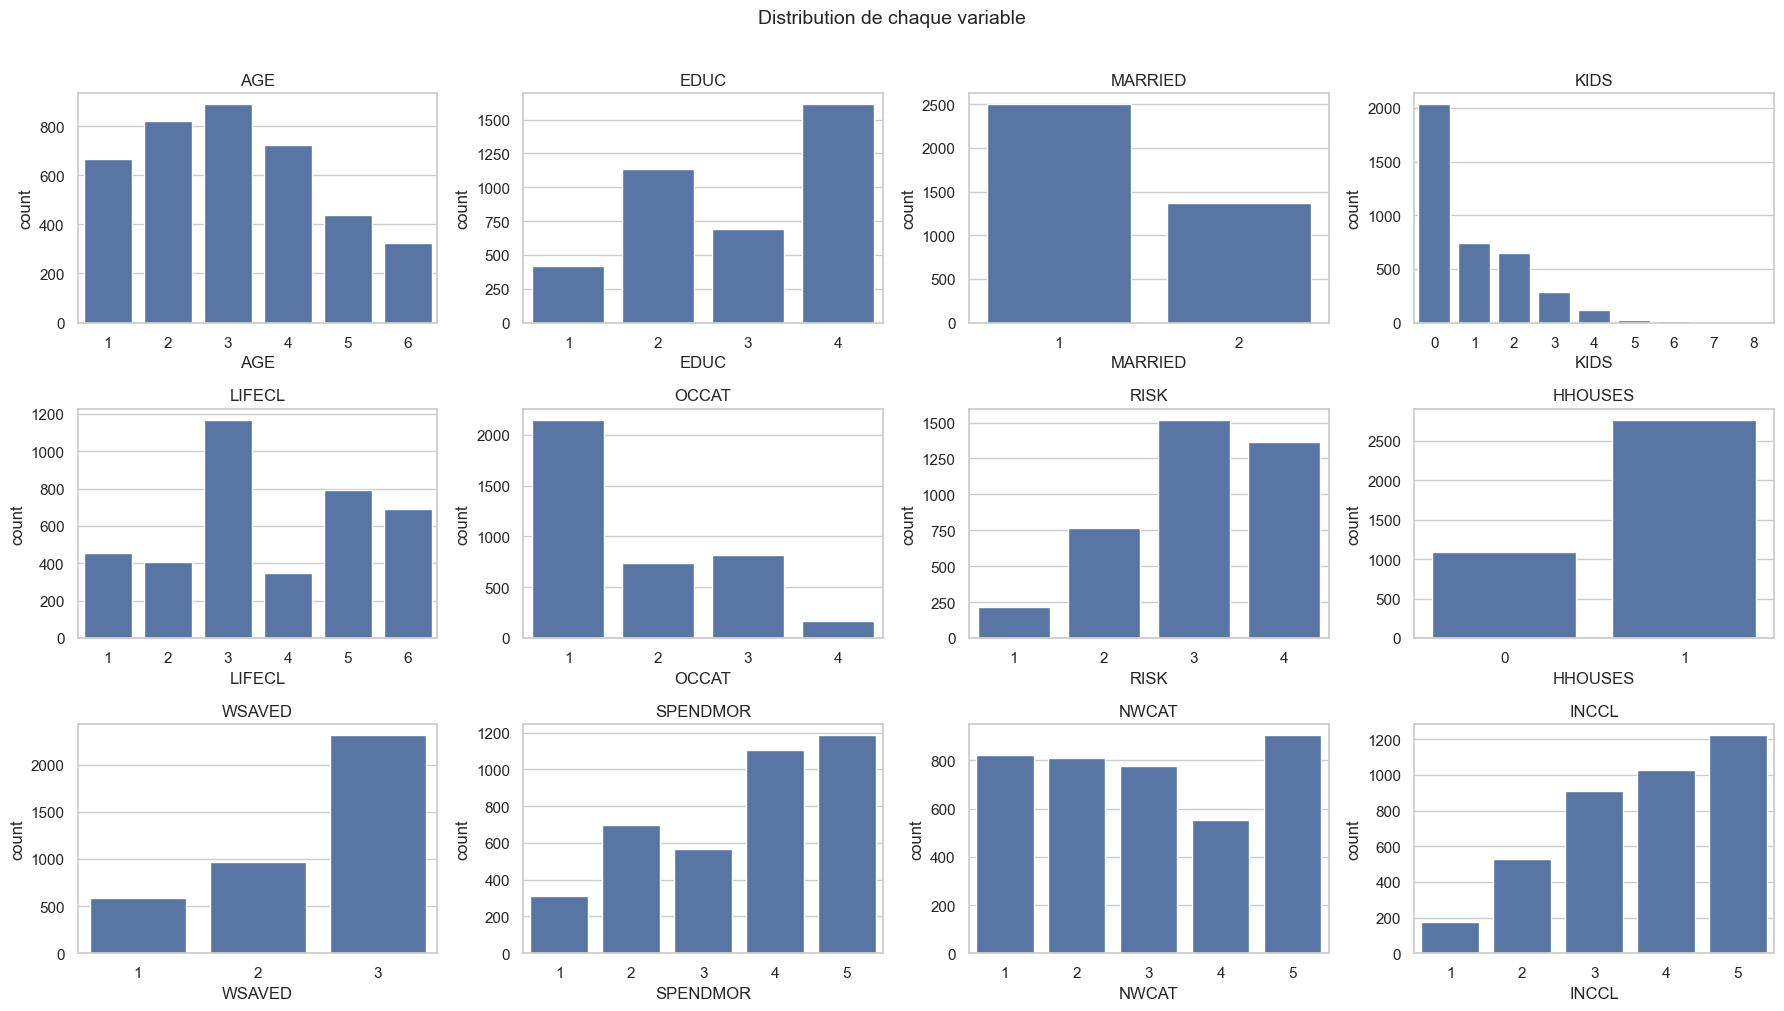

In [4]:
features_all = [c for c in df.columns if c != "ID"]
fig, axes = plt.subplots(3, 4, figsize=(18, 10))
for ax, col in zip(axes.ravel(), features_all):
    sns.countplot(x=col, data=df, ax=ax, color="#4C72B0")
    ax.set_title(col)
plt.suptitle("Distribution de chaque variable", y=1.01, fontsize=14)
plt.tight_layout(); plt.show()

**Pourquoi :** on repère les variables asymétriques (ex. `KIDS` : beaucoup d'individus sans enfant) et on vérifie que les codes sont cohérents.

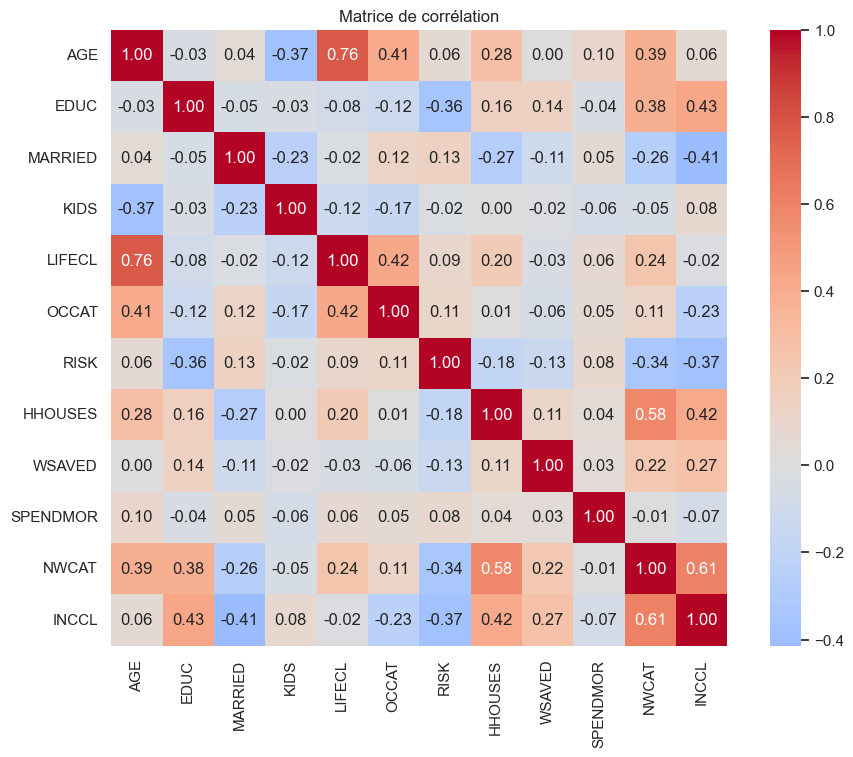

Paires les plus corrélées :
AGE      LIFECL    0.76
NWCAT    INCCL     0.61
HHOUSES  NWCAT     0.58
EDUC     INCCL     0.43
LIFECL   OCCAT     0.42
HHOUSES  INCCL     0.42
MARRIED  INCCL    -0.41
AGE      OCCAT     0.41
dtype: float64


In [5]:
plt.figure(figsize=(11, 8))
corr = df[features_all].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Matrice de corrélation"); plt.show()

pairs = corr.where(np.triu(np.ones(corr.shape), 1).astype(bool)).stack().sort_values(key=abs, ascending=False)
print("Paires les plus corrélées :"); print(pairs.head(8).round(2))

**Lecture :**
- `AGE` et `LIFECL` sont très corrélées (≈ 0,76) : elles portent presque la même information. Cela compte pour K-Means, qui utilise des distances.
- `NWCAT`, `INCCL` et `HHOUSES` sont corrélées entre elles : ce sont des indicateurs de **capacité** financière.
- `RISK` est négativement corrélée à l'éducation, au revenu et au patrimoine : les plus aisés déclarent plus de tolérance au risque (rappel : plus `RISK` est bas, plus la volonté est élevée).

## 3. Préparation des données

In [6]:
# 1) On retire ID (simple numéro) ; 2) on standardise pour que toutes les variables pèsent autant
X_df = df.drop(columns="ID")
scaler = StandardScaler()
X = scaler.fit_transform(X_df)
print("Matrice standardisée :", X.shape)

Matrice standardisée : (3866, 12)


**Pourquoi standardiser :** `KIDS` va de 0 à 8 alors que `HHOUSES` va de 0 à 1. Sans mise à l'échelle, les variables à grande amplitude domineraient le calcul des distances.

**Test de la redondance `AGE`/`LIFECL` :** on vérifie si retirer `LIFECL` change fortement la qualité du clustering.

In [18]:
X_nolife = StandardScaler().fit_transform(X_df.drop(columns="LIFECL"))
for name, M in [("Toutes les variables", X), ("Sans LIFECL", X_nolife)]:
    km = KMeans(5, n_init=10, random_state=RANDOM_STATE).fit(M)
    print(f"{name:22s} silhouette (k=5) = {silhouette_score(M, km.labels_):.3f}")

Toutes les variables   silhouette (k=5) = 0.132
Sans LIFECL            silhouette (k=5) = 0.128


On garde toutes les variables (le résultat est comparable et on conserve l'information du cycle de vie). Vous pouvez justifier l'autre choix dans le rapport si la silhouette s'améliore nettement.

## 4. Réduction de dimension (ACP)

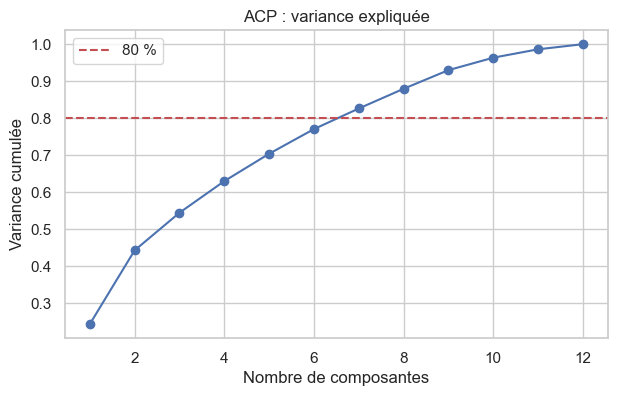

Composantes pour 80 % de variance : 7
Variance expliquée par PC1+PC2 : 0.443


In [8]:
pca_full = PCA().fit(X)
cum = np.cumsum(pca_full.explained_variance_ratio_)
plt.figure(figsize=(7, 4))
plt.plot(range(1, len(cum)+1), cum, "o-")
plt.axhline(0.8, color="r", ls="--", label="80 %")
plt.xlabel("Nombre de composantes"); plt.ylabel("Variance cumulée"); plt.legend(); plt.title("ACP : variance expliquée")
plt.show()
print("Composantes pour 80 % de variance :", int(np.argmax(cum >= 0.8)) + 1)

pca2 = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca2.fit_transform(X)
print("Variance expliquée par PC1+PC2 :", pca2.explained_variance_ratio_.sum().round(3))

**Pourquoi :** l'ACP sert surtout à **visualiser** les clusters en 2D. Les clusters sont calculés sur les données standardisées complètes, pas sur l'ACP, pour ne pas perdre d'information.

## 5. Choix du nombre de clusters *k*

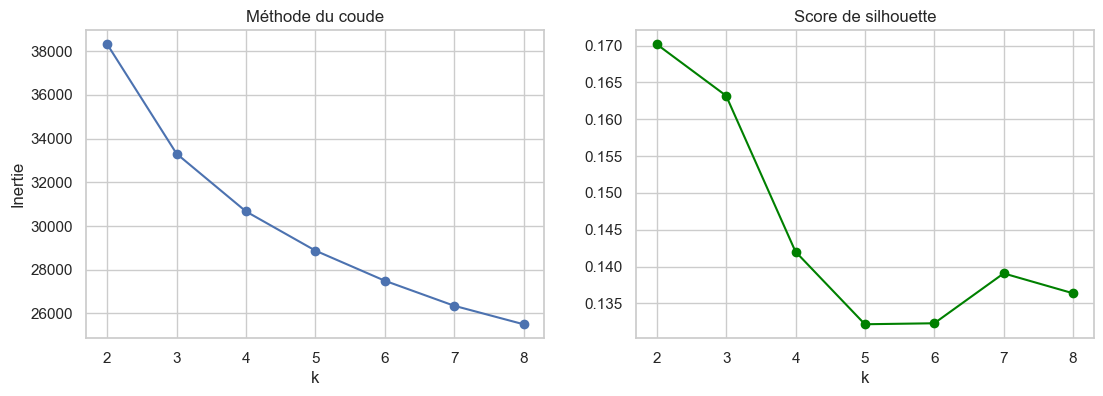

,k,inertie,silhouette
0,2,38318.0,0.170
1,3,33309.0,0.163
2,4,30669.0,0.142
3,5,28876.0,0.132
4,6,27498.0,0.132
5,7,26353.0,0.139
6,8,25506.0,0.136


In [9]:
ks = range(2, 9)
inertia, sil = [], []
for k in ks:
    km = KMeans(k, n_init=10, random_state=RANDOM_STATE).fit(X)
    inertia.append(km.inertia_); sil.append(silhouette_score(X, km.labels_))

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(ks, inertia, "o-"); ax[0].set_title("Méthode du coude"); ax[0].set_xlabel("k"); ax[0].set_ylabel("Inertie")
ax[1].plot(ks, sil, "o-", color="green"); ax[1].set_title("Score de silhouette"); ax[1].set_xlabel("k")
plt.show()
pd.DataFrame({"k": list(ks), "inertie": np.round(inertia), "silhouette": np.round(sil, 3)})

**Lecture :** les silhouettes sont faibles (< 0,2). Les groupes ne sont donc pas nettement séparés, ce qui est courant avec des données de comportement humain. Le choix de *k* combine la métrique et l'**interprétabilité métier**. On retient **k = 4** : les profils sont plus riches qu'avec 2 ou 3 groupes et chaque groupe reste assez grand.

## 6. K-Means (modèle principal) et profilage

In [21]:
K = 5
km = KMeans(K, n_init=10, random_state=RANDOM_STATE).fit(X)
df["Cluster_KMeans"] = km.labels_
print("Taille des clusters :"); print(df["Cluster_KMeans"].value_counts().sort_index())

profile = df.groupby("Cluster_KMeans")[features_all].mean().round(2)
profile

Taille des clusters :
Cluster_KMeans
0    859
1    807
2    823
3    779
4    598
Name: count, dtype: int64


,AGE,EDUC,MARRIED,KIDS,LIFECL,OCCAT,RISK,HHOUSES,WSAVED,SPENDMOR,NWCAT,INCCL
Cluster_KMeans,,,,,,,,,,,,
0,1.89,2.58,1.55,1.08,2.68,1.54,3.33,0.01,2.31,3.45,1.36,2.80
1,4.64,3.41,1.17,0.30,5.32,2.05,2.76,0.96,2.67,3.57,4.39,4.50
2,2.40,3.65,1.17,1.56,2.71,1.42,2.34,0.94,2.81,3.45,4.01,4.70
3,2.25,2.53,1.26,1.35,2.71,1.27,3.35,1.00,2.18,3.51,2.52,3.57
4,4.88,2.15,1.69,0.20,5.60,2.67,3.58,0.74,2.19,3.94,2.55,2.52


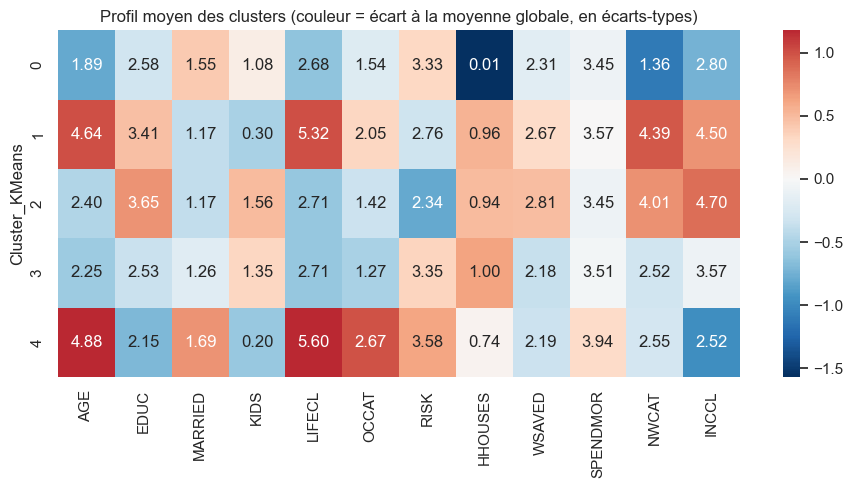

In [22]:
plt.figure(figsize=(11, 4.5))
prof_z = (profile - df[features_all].mean()) / df[features_all].std()
sns.heatmap(prof_z, annot=profile, fmt=".2f", cmap="RdBu_r", center=0)
plt.title("Profil moyen des clusters (couleur = écart à la moyenne globale, en écarts-types)")
plt.show()

**Comment lire :** rouge = valeur plus élevée que la moyenne, bleu = plus basse. Attention à `RISK` : une valeur **élevée** signifie une **faible** volonté de prendre des risques.

Interprétez ensuite chaque cluster avec ses valeurs. Avec `random_state=42` les numéros peuvent différer de mes essais : adaptez le dictionnaire de noms ci-dessous selon votre tableau.

In [23]:
# --- À ADAPTER selon le tableau 'profile' ci-dessus ---
# Règles de lecture :
#  - AGE/LIFECL élevés = seniors ; NWCAT/INCCL élevés = capacité forte ; RISK bas = volonté forte
def auto_name(row):
    age = "Seniors" if row.AGE >= 3.5 else "Jeunes/actifs"
    cap = "aisés" if (row.NWCAT + row.INCCL)/2 >= 3.3 else "modestes"
    vol = "tolérants au risque" if row.RISK <= 3.0 else "prudents"
    return f"{age} {cap}, {vol}"

names = {c: f"C{c} - " + auto_name(r) for c, r in profile.iterrows()}
df["Profil"] = df["Cluster_KMeans"].map(names)
pd.DataFrame({"Profil": pd.Series(names), "Effectif": df["Cluster_KMeans"].value_counts().sort_index()})

,Profil,Effectif
0,"C0 - Jeunes/actifs modestes, prudents",859
1,"C1 - Seniors aisés, tolérants au risque",807
2,"C2 - Jeunes/actifs aisés, tolérants au risque",823
3,"C3 - Jeunes/actifs modestes, prudents",779
4,"C4 - Seniors modestes, prudents",598


## 7. Les 3 autres modèles : hiérarchique, Gaussian Mixture et DBSCAN

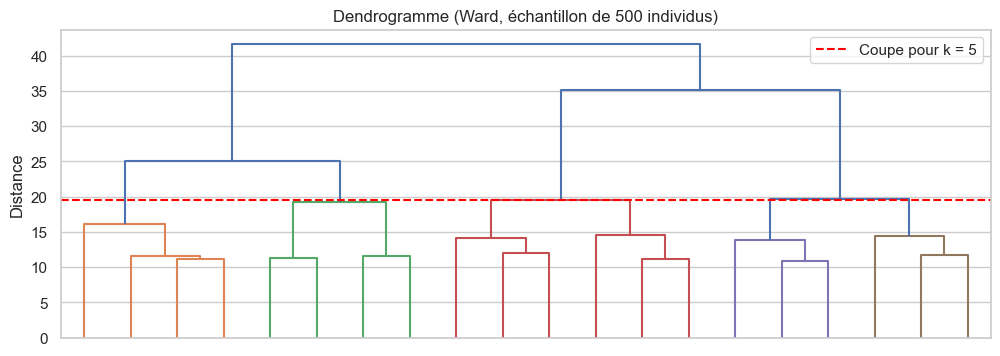

In [29]:
K = 5
sample = np.random.RandomState(RANDOM_STATE).choice(len(X), 500, replace=False)
Z = linkage(X[sample], method="ward")

# hauteur de coupe qui donne exactement K groupes
seuil = (Z[-K, 2] + Z[-(K-1), 2]) / 2

plt.figure(figsize=(12, 4))
dendrogram(Z, truncate_mode="lastp", p=20, no_labels=True, color_threshold=seuil)
plt.axhline(seuil, color="red", ls="--", label=f"Coupe pour k = {K}")
plt.title("Dendrogramme (Ward, échantillon de 500 individus)")
plt.ylabel("Distance"); plt.legend(); plt.show()

Hiérarchique : {0: 752, 1: 752, 2: 1072, 3: 835, 4: 455}
GMM          : {0: 1170, 1: 248, 2: 1383, 3: 594, 4: 471}


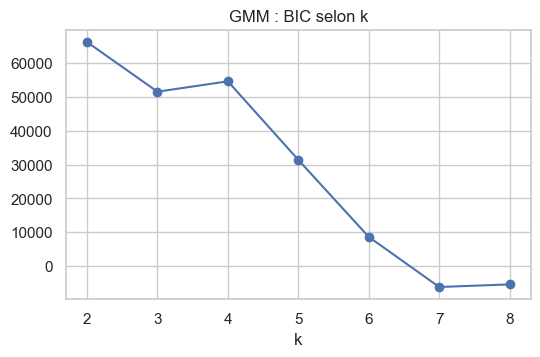

In [30]:
hc = AgglomerativeClustering(n_clusters=K, linkage="ward").fit(X)
df["Cluster_Hier"] = hc.labels_

gmm = GaussianMixture(n_components=K, covariance_type="full", n_init=5, random_state=RANDOM_STATE).fit(X)
df["Cluster_GMM"] = gmm.predict(X)

print("Hiérarchique :", df["Cluster_Hier"].value_counts().sort_index().to_dict())
print("GMM          :", df["Cluster_GMM"].value_counts().sort_index().to_dict())

# BIC du GMM pour différents k (critère complémentaire)
bics = [GaussianMixture(k, n_init=3, random_state=RANDOM_STATE).fit(X).bic(X) for k in range(2, 9)]
plt.figure(figsize=(6, 3.5)); plt.plot(range(2, 9), bics, "o-"); plt.title("GMM : BIC selon k"); plt.xlabel("k"); plt.show()

### DBSCAN
DBSCAN ne demande pas *k* : il détecte des zones **denses** et classe le reste comme **bruit** (étiquette -1). Deux paramètres : `eps` (rayon) et `min_samples`. On trace d'abord le graphique des distances au k-ième voisin pour guider le choix de `eps`, puis on teste une grille.

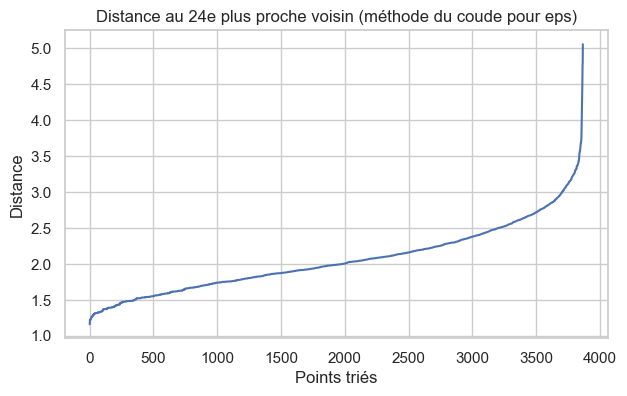

In [31]:
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors

MIN_SAMPLES = 2 * X.shape[1]          # règle usuelle : 2 x nombre de variables
kdist = np.sort(NearestNeighbors(n_neighbors=MIN_SAMPLES).fit(X).kneighbors(X)[0][:, -1])
plt.figure(figsize=(7, 4)); plt.plot(kdist)
plt.title(f"Distance au {MIN_SAMPLES}e plus proche voisin (méthode du coude pour eps)")
plt.xlabel("Points triés"); plt.ylabel("Distance"); plt.show()

In [32]:
rows = []
for ms in [12, MIN_SAMPLES]:
    for eps in [1.5, 1.8, 2.0, 2.2, 2.5]:
        lab = DBSCAN(eps=eps, min_samples=ms).fit_predict(X)
        n_cl = len(set(lab)) - (1 if -1 in lab else 0)
        mask = lab != -1
        sil_db = silhouette_score(X[mask], lab[mask]) if n_cl > 1 else np.nan
        rows.append({"min_samples": ms, "eps": eps, "clusters": n_cl,
                     "% bruit": round((~mask).mean()*100, 1), "silhouette": round(sil_db, 3)})
grid = pd.DataFrame(rows); print(grid.to_string(index=False))

# Sélection : au moins 3 clusters, bruit <= 30 %, meilleure silhouette
ok = grid[(grid.clusters >= 3) & (grid["% bruit"] <= 30)]
best = ok.sort_values("silhouette", ascending=False).iloc[0]
print("\nParamètres retenus :", best.to_dict())
db = DBSCAN(eps=best.eps, min_samples=int(best.min_samples)).fit(X)
df["Cluster_DBSCAN"] = db.labels_
print("Tailles (−1 = bruit) :", df["Cluster_DBSCAN"].value_counts().sort_index().to_dict())

 min_samples  eps  clusters  % bruit  silhouette
          12  1.5        16     48.3      -0.015
          12  1.8         9     19.0       0.097
          12  2.0         6     10.3       0.107
          12  2.2         2      5.2       0.187
          12  2.5         1      1.7         NaN
          24  1.5         4     69.8       0.152
          24  1.8         7     34.3       0.099
          24  2.0         7     17.8       0.100
          24  2.2         2      9.2       0.193
          24  2.5         1      2.9         NaN

Paramètres retenus : {'min_samples': 12.0, 'eps': 2.0, 'clusters': 6.0, '% bruit': 10.3, 'silhouette': 0.107}
Tailles (−1 = bruit) : {-1: 400, 0: 1932, 1: 346, 2: 224, 3: 477, 4: 313, 5: 174}


**Lecture :** les variables sont **discrètes** (codes de 1 à 5, par exemple) : beaucoup d'individus sont presque identiques et les données forment un nuage continu sans « trous » nets. DBSCAN a donc du mal : soit il fusionne presque tout en un seul gros cluster, soit il déclare beaucoup de points comme bruit. C'est un résultat à présenter honnêtement : DBSCAN est testé mais il est **moins adapté** à ces données que K-Means.

## 8. Comparaison et validation des 4 modèles

              Nb clusters  Silhouette (↑)  Davies-Bouldin (↓)  \
Modèle                                                          
K-Means                 5           0.132               2.069   
Hiérarchique            5           0.103               2.319   
GMM                     5           0.126               2.126   
DBSCAN                  6           0.107               1.879   

              Calinski-Harabasz (↑)  
Modèle                               
K-Means                     585.531  
Hiérarchique                444.185  
GMM                         448.311  
DBSCAN                      336.835  


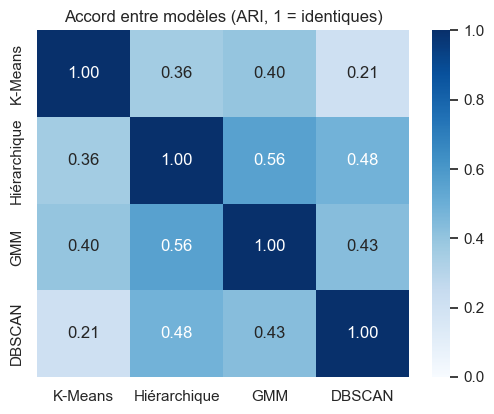

In [33]:
labels = {"K-Means": df["Cluster_KMeans"], "Hiérarchique": df["Cluster_Hier"], "GMM": df["Cluster_GMM"], "DBSCAN": df["Cluster_DBSCAN"]}
rows = []
for name, lab in labels.items():
    m = (lab != -1).values            # DBSCAN : on exclut le bruit du calcul des métriques
    rows.append({"Modèle": name,
                 "Nb clusters": len(set(lab[m])),
                 "Silhouette (↑)": silhouette_score(X[m], lab[m]),
                 "Davies-Bouldin (↓)": davies_bouldin_score(X[m], lab[m]),
                 "Calinski-Harabasz (↑)": calinski_harabasz_score(X[m], lab[m])})
comparison = pd.DataFrame(rows).set_index("Modèle").round(3)
display(comparison) if "display" in globals() else print(comparison)

# Accord entre modèles (ARI), calculé hors bruit DBSCAN
names_m = list(labels)
ari = pd.DataFrame(index=names_m, columns=names_m, dtype=float)
for a in names_m:
    for b in names_m:
        m = ((labels[a] != -1) & (labels[b] != -1)).values
        ari.loc[a, b] = adjusted_rand_score(labels[a][m], labels[b][m])
plt.figure(figsize=(6, 4.5)); sns.heatmap(ari.astype(float), annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1)
plt.title("Accord entre modèles (ARI, 1 = identiques)"); plt.show()

In [34]:
# Stabilité de K-Means : on relance avec plusieurs graines et on compare à la référence
ref = KMeans(K, n_init=10, random_state=0).fit(X).labels_
aris = [adjusted_rand_score(ref, KMeans(K, n_init=1, random_state=s).fit(X).labels_) for s in range(1, 21)]
print(f"ARI moyen sur 20 relances : {np.mean(aris):.3f} (min {np.min(aris):.3f})")

ARI moyen sur 20 relances : 0.735 (min 0.574)


**Lecture :** les métriques de DBSCAN sont calculées **hors bruit** et avec un nombre de clusters différent : elles ne sont pas strictement comparables aux trois autres modèles (à préciser dans le rapport). On retient le modèle avec les meilleures métriques *et* des profils interprétables. K-Means est en général le meilleur compromis (simple, stable, facile à expliquer). Un ARI moyen élevé sur les relances indique des clusters stables ; un ARI faible entre modèles montre que la structure est floue, ce qu'il faut mentionner dans les limites.

## 9. Visualisation et interprétation

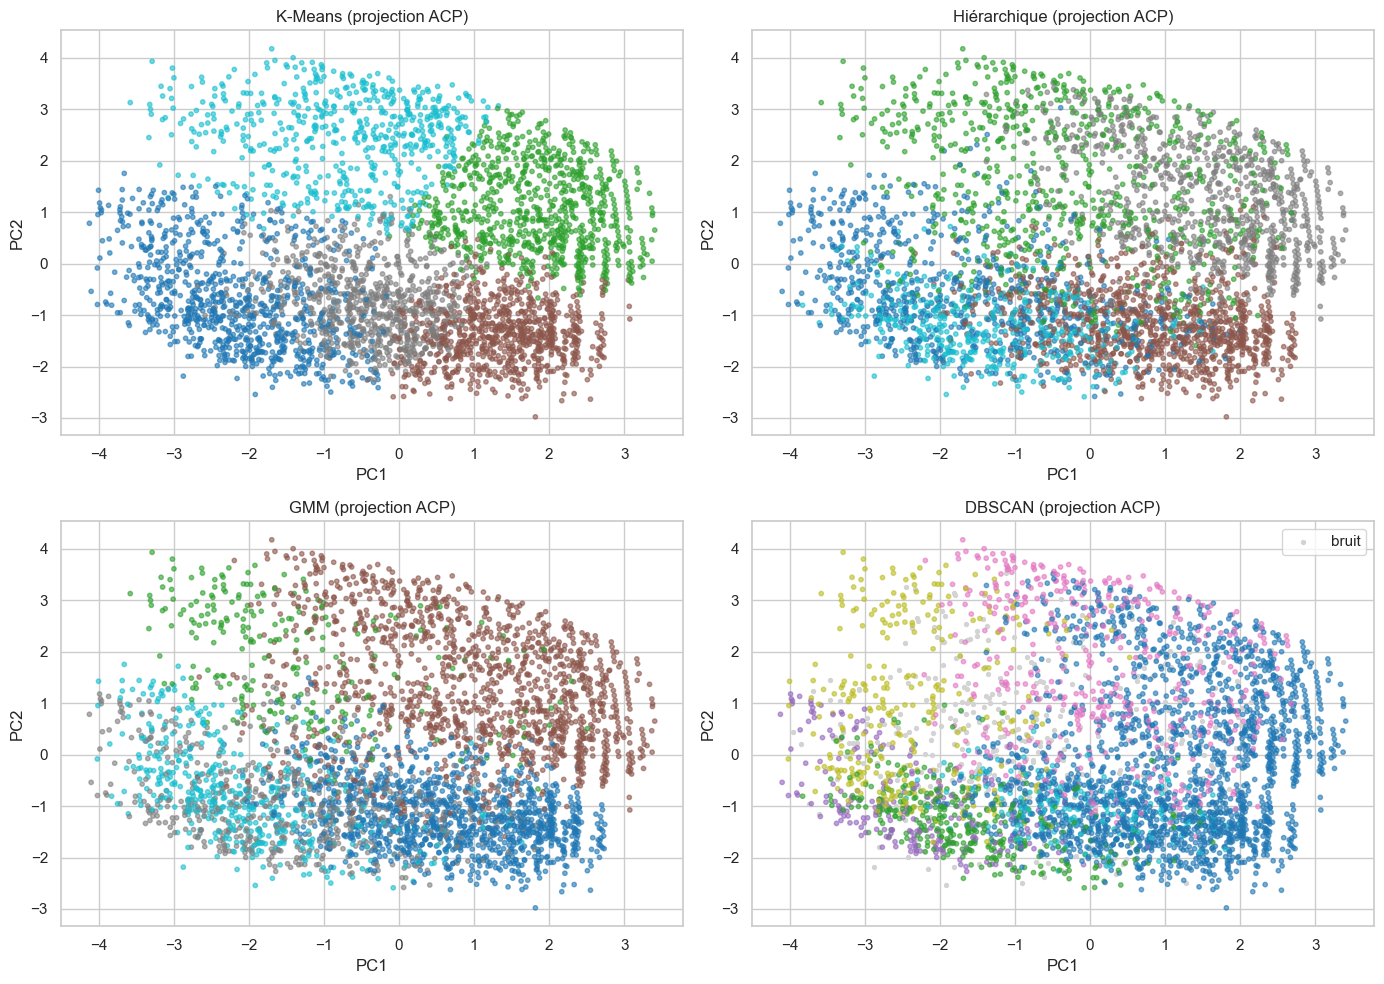

In [35]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for ax, (name, lab) in zip(axes.ravel(), labels.items()):
    lab = np.asarray(lab); noise = lab == -1
    ax.scatter(X_pca[noise, 0], X_pca[noise, 1], c="lightgrey", s=8, label="bruit")
    ax.scatter(X_pca[~noise, 0], X_pca[~noise, 1], c=lab[~noise], cmap="tab10", s=10, alpha=0.6)
    ax.set_title(f"{name} (projection ACP)"); ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
    if noise.any(): ax.legend()
plt.tight_layout(); plt.show()

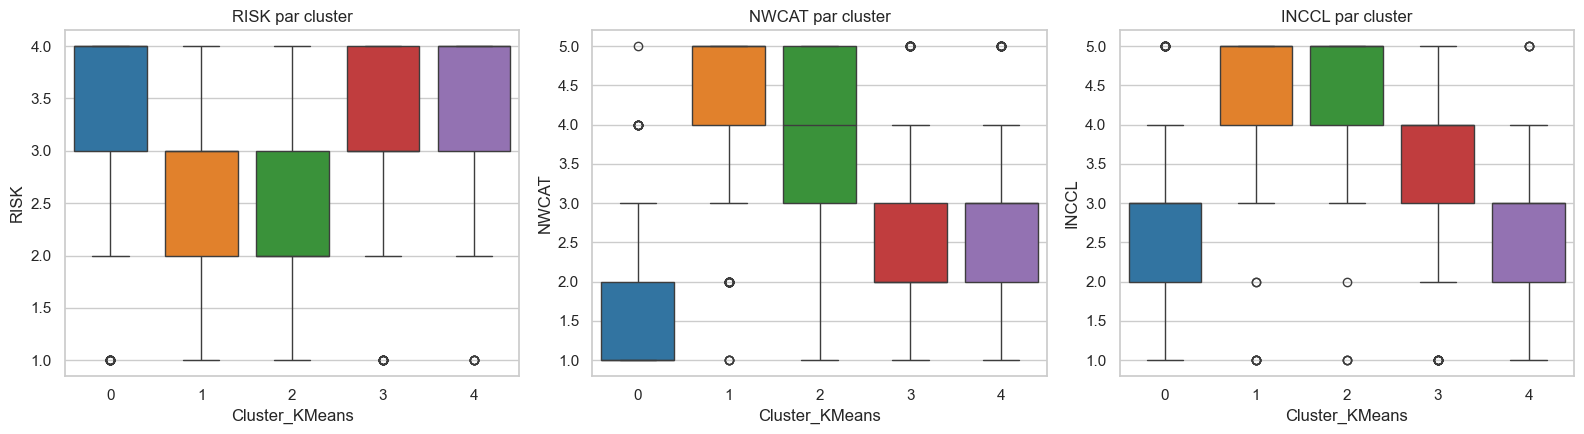

In [36]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, col in zip(axes, ["RISK", "NWCAT", "INCCL"]):
    sns.boxplot(x="Cluster_KMeans", y=col, data=df, ax=ax, palette="tab10")
    ax.set_title(f"{col} par cluster")
plt.tight_layout(); plt.show()

### Capacité vs volonté de prendre des risques
On résume chaque individu par deux scores simples :
- **Capacité** = moyenne standardisée de `NWCAT`, `INCCL`, `HHOUSES` (patrimoine, revenu, propriété).
- **Volonté** = `RISK` inversé (plus la valeur est haute, plus l'individu accepte le risque).

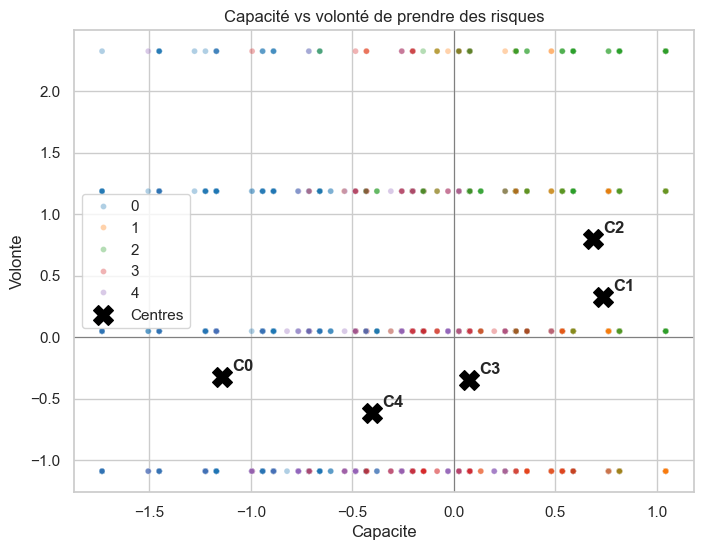

,Capacite,Volonte
Cluster_KMeans,,
0,-1.14,-0.33
1,0.74,0.33
2,0.69,0.80
3,0.08,-0.35
4,-0.40,-0.61


In [37]:
z = lambda s: (s - s.mean()) / s.std()
df["Capacite"] = (z(df["NWCAT"]) + z(df["INCCL"]) + z(df["HHOUSES"])) / 3
df["Volonte"] = -z(df["RISK"])

plt.figure(figsize=(8, 6))
sns.scatterplot(data=df, x="Capacite", y="Volonte", hue="Cluster_KMeans", palette="tab10", alpha=0.35, s=18)
cent = df.groupby("Cluster_KMeans")[["Capacite", "Volonte"]].mean()
plt.scatter(cent.Capacite, cent.Volonte, c="black", s=200, marker="X", label="Centres")
for c, r in cent.iterrows(): plt.text(r.Capacite + 0.05, r.Volonte + 0.05, f"C{c}", fontsize=12, weight="bold")
plt.axhline(0, color="grey", lw=.8); plt.axvline(0, color="grey", lw=.8)
plt.title("Capacité vs volonté de prendre des risques"); plt.legend(); plt.show()
cent.round(2)

**Lecture :** le cadran en haut à droite regroupe les investisseurs qui ont à la fois la capacité et la volonté de prendre des risques (cibles pour des produits plus risqués). Le cadran en bas à gauche regroupe ceux qui n'ont ni l'une ni l'autre (produits prudents, épargne de précaution).

## 10. Conclusion et export

In [38]:
out = df[["ID", "Cluster_KMeans", "Profil", "Cluster_Hier", "Cluster_GMM", "Cluster_DBSCAN", "Capacite", "Volonte"]]
out.to_excel("resultats_clustering.xlsx", index=False)
profile.to_excel("profils_clusters.xlsx")
print("Fichiers exportés : resultats_clustering.xlsx, profils_clusters.xlsx")

Fichiers exportés : resultats_clustering.xlsx, profils_clusters.xlsx
